# 08 – Regression, embeddings and semantic segmentation (L11, L13, L07 project transfers)

Three GeoAI methods from the course applied to the same early-warning question as notebook 06, now **per pixel** instead of per canopy unit:

> Given the Sentinel-2 late-summer images of 2017 (before the drought) and 2018 (drought year), what happens to the canopy in the following years?

| Part | Lesson | Target | Model | Train → test |
|---|---|---|---|---|
| A | L11 regression | ΔNDVI 2019 − 2017 (continuous) | linear baseline, Random Forest, U-Net (`geoai.train_pixel_regressor`) | Fricktal → Ajoie |
| B | L13 embeddings | embedding change 2017 → 2019; decline class | TESSERA 128-d pixel embeddings, cosine similarity, Random Forest | within the Ajoie core tile, spatial block CV |
| C | L07 semantic segmentation | persistent decline (binary, weak labels) | U-Net (`geoai.train_segmentation_model`) vs Random Forest | Fricktal → Ajoie |

**Shared rules.** Inputs never include data from the target year. Splits are region-based (train and validation in different parts of the Fricktal, test in the Ajoie). All targets are derived from Sentinel-2 itself (no field labels exist, see notebook 06), so the scores describe how predictable the spectral decline is. They are not accuracies of a tree-health map.

In [1]:
import os, sys, json, shutil, warnings
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"   # conda and pip builds of OpenMP clash on macOS ...
os.environ["OMP_NUM_THREADS"] = "1"           # ... and crash the kernel during training unless OpenMP stays single-threaded
import torch, geoai                            # import torch BEFORE numpy/scikit-learn: the other order crashed the kernel during training
from pathlib import Path
sys.path.append(str(Path("..").resolve() / "scripts"))   # folder containing sds_utils.py

import numpy as np, pandas as pd, xarray as xr
import rasterio
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.metrics import (r2_score, mean_absolute_error, precision_recall_fscore_support, jaccard_score,
                             average_precision_score, roc_auc_score)
from scipy.stats import spearmanr
import sds_utils as su
warnings.filterwarnings("ignore")
import logging; logging.getLogger("lightning.pytorch").setLevel(logging.WARNING)

SEED = 42
TRAIN_AOI, TEST_AOI = "fricktal_ag", "ajoie_ju"
IN_YEARS, WIN = (2017, 2018), "late"
TILE = 64                              # 640 m tiles: several stands of context, many tiles per AOI
VAL_FRAC = 0.25                        # eastern quarter of the Fricktal = validation region
Z_THR = -1.5                           # same relative threshold as notebook 07
TARGET_SCALE = 20                      # U-Net regression target = ΔNDVI × 20 (see part A)
RETRAIN = False                        # True: retrain the U-Nets even if checkpoints exist
TILES, MODELS = su.PROC / "tiles", su.PROC / "models"
TILES.mkdir(exist_ok=True); MODELS.mkdir(exist_ok=True)
DEVICE = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
np.random.seed(SEED); torch.manual_seed(SEED)
print("device:", DEVICE, "| geoai", geoai.__version__)

device: mps | geoai 0.43.1


## 0 · Shared inputs and targets
Input stack: nine bands of late summer 2017 and nine of 2018 (18 channels). Targets: ΔNDVI 2019 − 2017 (regression) and *persistent decline* = relative NDVI drop in 2019 **and** 2020 (segmentation), both on forest pixels only.

In [2]:
def layers(aoi):
    comp = {y: su.open_composite(aoi, y, WIN) for y in IN_YEARS}
    X = np.stack([comp[y][b].values for y in IN_YEARS for b in su.S2_BANDS]).astype("float32")     # (18, H, W)
    idx = {f"{v}_{y}": comp[y][v].values for y in IN_YEARS for v in ("NDVI", "NDMI", "NBR", "NDRE")}
    forest = su.load_ancillary(aoi)["forest"].values == 1
    d19, d20 = su.index_delta(aoi, "NDVI", 2019), su.index_delta(aoi, "NDVI", 2020)
    ok = forest & np.isfinite(d19) & np.isfinite(d20) & np.isfinite(X).all(0)
    persistent = (su.robust_z(d19) <= Z_THR) & (su.robust_z(d20) <= Z_THR)
    return dict(X=X, idx=idx, ok=ok, y_reg=np.where(ok, d19, np.nan), y_seg=persistent & ok,
                d18=su.index_delta(aoi, "NDVI", 2018), grid=su.aoi_grid(aoi))

L = {a: layers(a) for a in (TRAIN_AOI, TEST_AOI)}
for a, l in L.items():
    print(f"{a}: {l['ok'].sum():,} valid forest pixels | persistent decline {l['y_seg'].sum() / l['ok'].sum():.2%} | "
          f"ΔNDVI 2019 median {np.nanmedian(l['y_reg']):+.3f}, sd {np.nanstd(l['y_reg']):.3f}")

def pixel_table(aoi, cols=None):
    # tabular view for the Random Forest baselines: 18 bands + 8 indices + 4 index changes
    l = L[aoi]; m = l["ok"] if cols is None else l["ok"] & cols
    f = {f"{b}_{y}": l["X"][i * 9 + j][m] for i, y in enumerate(IN_YEARS) for j, b in enumerate(su.S2_BANDS)}
    f.update({k: v[m] for k, v in l["idx"].items()})
    for v in ("NDVI", "NDMI", "NBR", "NDRE"): f[f"d{v}_2018"] = f[f"{v}_2018"] - f[f"{v}_2017"]
    df = pd.DataFrame(f).fillna(0)
    rr, cc = np.nonzero(m)
    return df, l["y_reg"][m], l["y_seg"][m], rr, cc

H, W = L[TRAIN_AOI]["ok"].shape
col_split = int(W * (1 - VAL_FRAC))
west = np.zeros((H, W), bool); west[:, :col_split] = True
Xtr_df, ytr_reg, ytr_seg, rtr, ctr = pixel_table(TRAIN_AOI, west)
Xva_df, yva_reg, yva_seg, _, _ = pixel_table(TRAIN_AOI, ~west)
Xte_df, yte_reg, yte_seg, rte, cte = pixel_table(TEST_AOI)
print(f"pixels: train {len(Xtr_df):,} (Fricktal west) | val {len(Xva_df):,} (Fricktal east) | test {len(Xte_df):,} (Ajoie)")

fricktal_ag: 628,258 valid forest pixels | persistent decline 2.08% | ΔNDVI 2019 median +0.010, sd 0.041
ajoie_ju: 654,291 valid forest pixels | persistent decline 2.71% | ΔNDVI 2019 median +0.003, sd 0.055
pixels: train 451,224 (Fricktal west) | val 177,034 (Fricktal east) | test 654,291 (Ajoie)


# Part A · Regression (L11)

**Plan.** Continuous target ΔNDVI 2019 − 2017, valid range [−1, 1], forest pixels only. Three models of increasing complexity, all trained in the western Fricktal, tuned on the eastern Fricktal, tested on the Ajoie:

1. **Linear baseline:** ΔNDVI 2019 = a + b · ΔNDVI 2018. Tests whether next-year change is just the drought-year change carried forward.
2. **Random Forest** on the pixel's own 30 features (no spatial context).
3. **U-Net pixel regressor** with a ResNet-34 encoder (`geoai.train_pixel_regressor`), which also sees the neighbourhood (640 m tiles). Huber loss, since harvested pixels are outliers.

Evaluation: RMSE, MAE, R² on Ajoie forest pixels, a residual map and an observed-vs-predicted plot.

In [3]:
def reg_metrics(y, p):
    return dict(rmse=float(np.sqrt(np.mean((y - p) ** 2))), mae=float(mean_absolute_error(y, p)), r2=float(r2_score(y, p)),
                spearman=float(spearmanr(y[::25], p[::25]).statistic))

reg_rows, reg_pred = [], {}
# 0) no-skill reference: predict the training mean
reg_rows.append(dict(model="mean of training target", **reg_metrics(yte_reg, np.full(len(yte_reg), ytr_reg.mean()))))
# 1) linear carry-forward baseline
lin = LinearRegression().fit(Xtr_df[["dNDVI_2018"]], ytr_reg)
reg_pred["linear"] = lin.predict(Xte_df[["dNDVI_2018"]])
reg_rows.append(dict(model=f"linear: {lin.intercept_:+.3f} {lin.coef_[0]:+.2f}·ΔNDVI2018", **reg_metrics(yte_reg, reg_pred["linear"])))
# 2) Random Forest on pixel features
rng = np.random.default_rng(SEED); sub = rng.choice(len(Xtr_df), min(60000, len(Xtr_df)), replace=False)
rf_reg = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, max_features=0.33, n_jobs=-1, random_state=SEED)
rf_reg.fit(Xtr_df.iloc[sub], ytr_reg[sub])
reg_pred["rf"] = rf_reg.predict(Xte_df)
reg_rows.append(dict(model="Random Forest (pixel features)", **reg_metrics(yte_reg, reg_pred["rf"])))
print("validation (Fricktal east) R2: linear %.3f | RF %.3f" % (r2_score(yva_reg, lin.predict(Xva_df[["dNDVI_2018"]])), r2_score(yva_reg, rf_reg.predict(Xva_df))))
pd.DataFrame(reg_rows).round(4)

validation (Fricktal east) R2: linear 0.434 | RF 0.510


,model,rmse,mae,r2,spearman
0,mean of training target,0.0555,0.0347,-0.0198,NaN
1,linear: +0.024 +0.61·ΔNDVI2018,0.0386,0.0252,0.5069,0.6320
2,Random Forest (pixel features),0.0345,0.0221,0.6069,0.6819


### U-Net pixel regressor
Rasters and tiles are written to `data/derived.nosync/tiles/`. Training tiles overlap by 50 % (more samples); validation tiles come from the eastern region and do not overlap the training region, so validation scores are not inflated by shared pixels.

Three details that a first run got wrong and that matter for any small-valued target:
- **Target scale.** ΔNDVI has a standard deviation of about 0.04. With the raw target the loss was tiny from the first step and the network learned almost nothing (validation R² ≈ 0). The target is therefore multiplied by 20 for training and divided again after prediction.
- **No-data targets.** `geoai` has no masked loss, so non-forest pixels get target 0 (no change). They are excluded from every metric.
- **Tile size at inference.** Predicting with 256 px tiles from a model trained on 64 px tiles produced values far outside the valid range. Inference uses the training tile size.

In [4]:
def write_tif(path, arr, aoi, nodata=None, dtype="float32"):
    arr = arr[None] if arr.ndim == 2 else arr                                  # (bands, H, W)
    with rasterio.open(path, "w", driver="GTiff", height=arr.shape[1], width=arr.shape[2], count=arr.shape[0], dtype=dtype,
                       crs=su.CRS_UTM, transform=L[aoi]["grid"][0], nodata=nodata, compress="deflate") as dst:
        dst.write(arr.astype(dtype))
    return str(path)

def make_tiles(aoi, name, x, y, cols, stride, min_forest=0.3, y_dtype="float32", y_nodata=-9999.0):
    # paired image / target tiles; a tile is kept if enough of it is valid forest
    out_x, out_y = TILES / name / "images", TILES / name / "labels"
    if out_x.exists(): shutil.rmtree(TILES / name)
    out_x.mkdir(parents=True); out_y.mkdir(parents=True)
    tr_ = L[aoi]["grid"][0]; ok = L[aoi]["ok"]; px, py = [], []
    for r in range(0, ok.shape[0] - TILE + 1, stride):
        for c in range(cols.start, cols.stop - TILE + 1, stride):
            sl = (slice(r, r + TILE), slice(c, c + TILE))
            if ok[sl].mean() < min_forest: continue
            t = rasterio.windows.transform(rasterio.windows.Window(c, r, TILE, TILE), tr_)
            for folder, arr, dt, nd, lst in ((out_x, x[(slice(None),) + sl], x.dtype.name, None, px), (out_y, y[sl][None], y_dtype, y_nodata, py)):
                p = folder / f"{aoi}_{r:04d}_{c:04d}.tif"
                with rasterio.open(p, "w", driver="GTiff", height=TILE, width=TILE, count=arr.shape[0], dtype=dt, crs=su.CRS_UTM,
                                   transform=t, nodata=nd) as dst:
                    dst.write(arr.astype(dt))
                lst.append(str(p))
    return px, py

lt = L[TRAIN_AOI]
x_float = np.nan_to_num(lt["X"], nan=0.0)                                     # reflectance 0-1
y_reg_img = np.where(lt["ok"], np.clip(lt["y_reg"], -1, 1) * TARGET_SCALE, 0.0).astype("float32")   # valid range enforced at tiling
tr_x, tr_y = make_tiles(TRAIN_AOI, "reg_train", x_float, y_reg_img, slice(0, col_split), stride=TILE // 2, y_nodata=None)
va_x, va_y = make_tiles(TRAIN_AOI, "reg_val", x_float, y_reg_img, slice(col_split, W), stride=TILE, y_nodata=None)
test_raster = write_tif(TILES / f"x_{TEST_AOI}.tif", np.nan_to_num(L[TEST_AOI]["X"], nan=0.0), TEST_AOI)
print(len(tr_x), "training tiles |", len(va_x), "validation tiles |", TILE, "px")

583 training tiles | 57 validation tiles | 64 px


In [5]:
reg_dir = MODELS / "unet_regression"
ckpts = sorted((reg_dir / "models").glob("*.ckpt")) if (reg_dir / "models").exists() else []
if RETRAIN or not ckpts:
    if reg_dir.exists(): shutil.rmtree(reg_dir)
    unet_reg = geoai.train_pixel_regressor(
        train_image_paths=tr_x, train_target_paths=tr_y, val_image_paths=va_x, val_target_paths=va_y,
        encoder_name="resnet34", architecture="unet", in_channels=18, encoder_weights="imagenet",
        output_dir=str(reg_dir), batch_size=32, num_epochs=80, learning_rate=1e-3, loss_type="huber",
        patience=12, accelerator=DEVICE if DEVICE != "cuda" else "gpu", verbose=False)
    ckpts = sorted((reg_dir / "models").glob("*.ckpt"))
best_ckpt = min(ckpts, key=lambda p: float(p.stem.split("val_loss=")[-1]) if "val_loss=" in p.stem else 9e9)
unet_reg = geoai.PixelRegressionModel.load_from_checkpoint(str(best_ckpt), map_location="cpu")
print("best checkpoint:", best_ckpt.name)

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

... (38 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

best checkpoint: resnet34_unet_epoch=32_val_loss=0.0880.ckpt


In [6]:
pred_path = geoai.predict_raster(unet_reg, test_raster, str(su.PROC / f"{TEST_AOI}_dndvi2019_unet.tif"),
                                 tile_size=TILE, overlap=TILE // 2, batch_size=32, device=DEVICE,
                                 clip_range=(-TARGET_SCALE, TARGET_SCALE))               # valid range enforced at inference
with rasterio.open(pred_path) as src: unet_img = src.read(1)
unet_img = np.where(unet_img > -9000, unet_img / TARGET_SCALE, np.nan)                  # back to ΔNDVI units
reg_pred["unet"] = unet_img[rte, cte]
miss = ~np.isfinite(reg_pred["unet"])
print(f"U-Net: {miss.mean():.2%} of forest pixels without prediction (filled with the training mean)")
reg_pred["unet"] = np.where(miss, ytr_reg.mean(), reg_pred["unet"])
reg_rows.append(dict(model="U-Net ResNet-34 (geoai pixel regressor)", **reg_metrics(yte_reg, reg_pred["unet"])))
reg_tbl = pd.DataFrame(reg_rows).round(4)
reg_tbl.to_csv(su.TABLES / "08_regression_test_ajoie.csv", index=False)
reg_tbl

Running inference:   0%|          | 0/55 [00:00<?, ?it/s]

U-Net: 0.40% of forest pixels without prediction (filled with the training mean)


,model,rmse,mae,r2,spearman
0,mean of training target,0.0555,0.0347,-0.0198,NaN
1,linear: +0.024 +0.61·ΔNDVI2018,0.0386,0.0252,0.5069,0.6320
2,Random Forest (pixel features),0.0345,0.0221,0.6069,0.6819
3,U-Net ResNet-34 (geoai pixel regressor),0.0434,0.0260,0.3788,0.5804


### Spatial check: observed vs predicted and residual map (Ajoie)

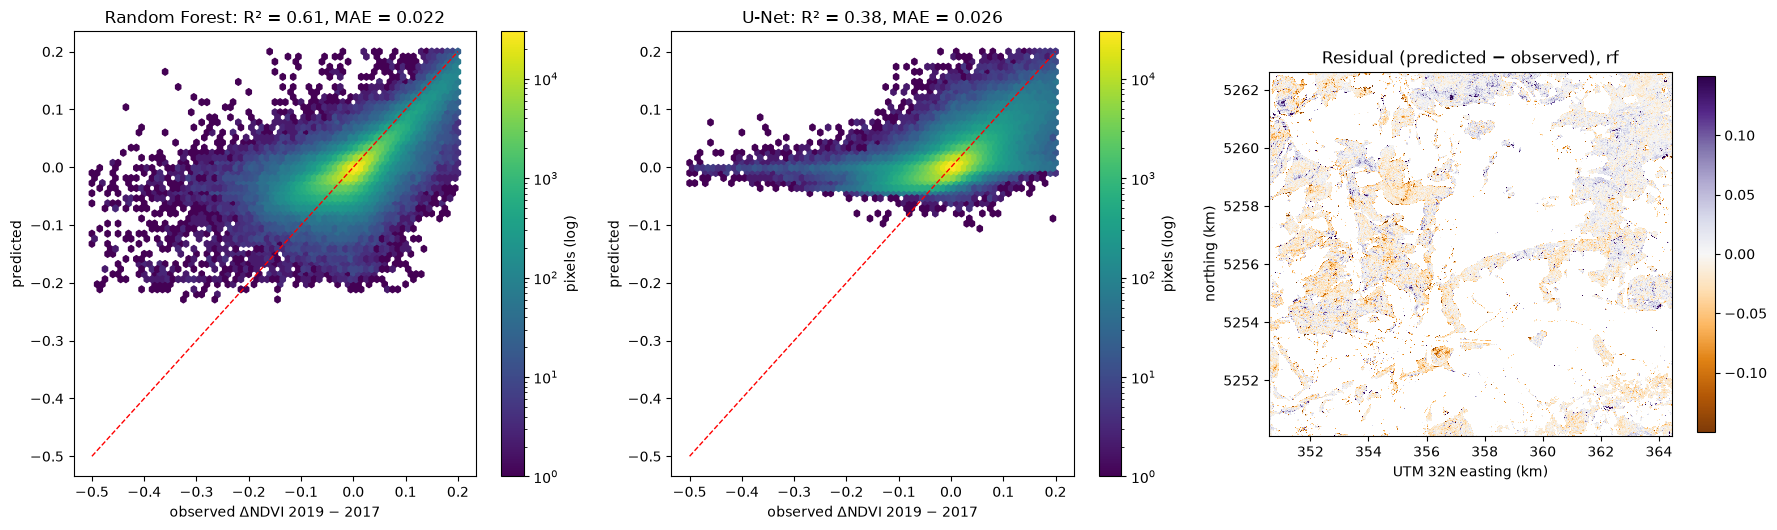

rf: residual on the 5 % strongest declines: mean +0.068 (positive = decline under-predicted) | rest -0.009


In [7]:
_, Wt, Ht, xs, ys = L[TEST_AOI]["grid"]; EXT = [xs[0] / 1e3, xs[-1] / 1e3, ys[-1] / 1e3, ys[0] / 1e3]
best_reg = max(("rf", "unet"), key=lambda k: r2_score(yte_reg, reg_pred[k]))
def to_img(v):
    img = np.full((Ht, Wt), np.nan, "float32"); img[rte, cte] = v; return img

fig, ax = plt.subplots(1, 3, figsize=(18, 5.4))
for a, (k, lab) in zip(ax[:2], (("rf", "Random Forest"), ("unet", "U-Net"))):
    hb = a.hexbin(yte_reg, reg_pred[k], gridsize=70, bins="log", extent=(-0.5, 0.2, -0.5, 0.2), cmap="viridis")
    a.plot([-0.5, 0.2], [-0.5, 0.2], "r--", lw=1); a.set_xlabel("observed ΔNDVI 2019 − 2017"); a.set_ylabel("predicted")
    a.set_title(f"{lab}: R² = {r2_score(yte_reg, reg_pred[k]):.2f}, MAE = {mean_absolute_error(yte_reg, reg_pred[k]):.3f}")
    plt.colorbar(hb, ax=a, label="pixels (log)")
im = ax[2].imshow(to_img(reg_pred[best_reg] - yte_reg), cmap="PuOr", norm=TwoSlopeNorm(0, -0.15, 0.15), extent=EXT, interpolation="nearest")
ax[2].set_title(f"Residual (predicted − observed), {best_reg}"); ax[2].set_xlabel("UTM 32N easting (km)"); ax[2].set_ylabel("northing (km)")
plt.colorbar(im, ax=ax[2], shrink=0.8)
plt.tight_layout(); plt.savefig(su.FIGS / "08_regression_scatter_residuals.png", dpi=150); plt.show()

res = reg_pred[best_reg] - yte_reg
strong = yte_reg <= np.quantile(yte_reg, 0.05)
print(f"{best_reg}: residual on the 5 % strongest declines: mean {res[strong].mean():+.3f} (positive = decline under-predicted) | rest {res[~strong].mean():+.3f}")

# Part B · Embeddings (L13)

**Plan.** TESSERA provides one 128-dimensional vector per 10 m pixel and year, learned from Sentinel-1 and Sentinel-2 time series. The dimensions are not wavelengths and cannot be interpreted one by one.

- **Goal 1 (change):** does the similarity between the 2017 and 2019 embeddings of a pixel flag the same places as ΔNDVI?
- **Goal 2 (features):** are the 2017 + 2018 embeddings better predictors of the persistent-decline class than the hand-made band and index features of part A?
- **Data:** one TESSERA tile (0.1°) covering the core of the Ajoie around Alle, Miécourt and Beurnevésin, years 2017–2019 (`geoai.tessera_download`, about 400 MB per year, 10 m, UTM 32N).
- **Labels:** the persistent-decline proxy for every forest pixel. No field labels.
- **Validation:** spatial block cross-validation (1 km blocks) inside the tile; average precision, ROC AUC, and F1 / IoU at a matched flagged share, since the class is rare.
- **What a good result would not prove:** that embeddings recognise tree health. It would only show they encode the spectral-temporal signal that defines the proxy.

In [8]:
TESS_BBOX = (7.11, 47.41, 7.19, 47.49)            # inside one 0.1 degree TESSERA tile
TESS_DIR = su.PROC / "tessera"
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling

def tessera_on_grid(year):
    # download (cached) and warp the 128 bands onto the project's Ajoie grid
    d = TESS_DIR / str(year)
    files = sorted(d.rglob("*.tif*")) if d.exists() else []
    if not files:
        files = [Path(f) for f in geoai.tessera_download(bbox=TESS_BBOX, year=year, output_dir=str(d), output_format="tiff")]
    tr_, w, h, _, _ = L[TEST_AOI]["grid"]
    with rasterio.open(files[0]) as src, WarpedVRT(src, crs=su.CRS_UTM, transform=tr_, width=w, height=h,
                                                    resampling=Resampling.nearest, src_nodata=None, nodata=np.nan, dtype="float32") as vrt:
        return vrt.read().astype("float32")

emb = {y: tessera_on_grid(y) for y in (2017, 2018, 2019)}
cover = np.isfinite(emb[2017]).all(0) & (np.abs(emb[2017]).sum(0) > 0)
m_e = cover & L[TEST_AOI]["ok"]
print("embedding shape:", emb[2017].shape, "| forest pixels with embeddings:", f"{m_e.sum():,}")

embedding shape: (128, 1256, 1387) | forest pixels with embeddings: 285,277


### B1 · Embedding change vs index change
Cosine similarity between the 2017 and 2019 vectors of each pixel (1 = unchanged). Compared with ΔNDVI on forest pixels.

Spearman(cosine similarity, ΔNDVI) = 0.21 | with −|ΔNDVI − median| = 0.26
persistent-decline pixels among the 5 % least similar pixels: 12.7% (all forest pixels in the tile: 2.5%)


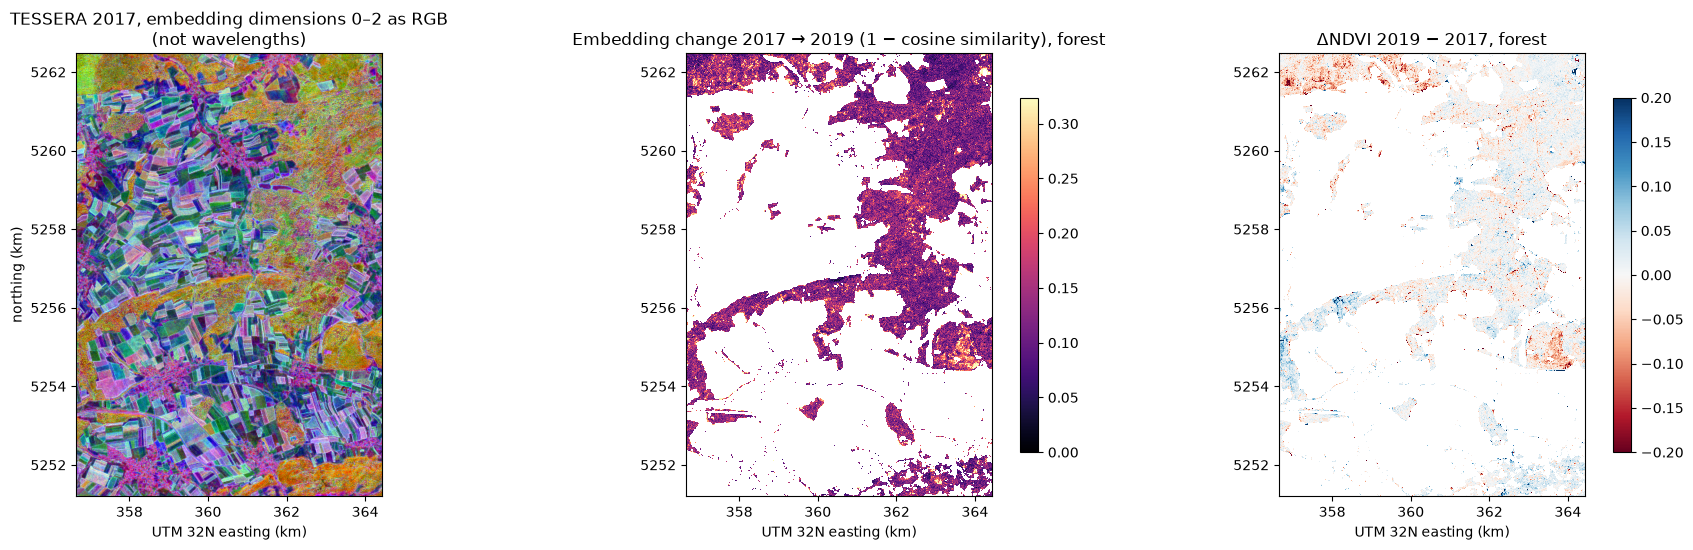

In [9]:
def cosine(a, b):
    return (a * b).sum(0) / (np.linalg.norm(a, axis=0) * np.linalg.norm(b, axis=0) + 1e-9)

cos1719 = np.where(m_e, cosine(emb[2017], emb[2019]), np.nan)
cos1718 = np.where(m_e, cosine(emb[2017], emb[2018]), np.nan)
d19 = L[TEST_AOI]["y_reg"]
rho = spearmanr(cos1719[m_e], d19[m_e]).statistic
rho_abs = spearmanr(cos1719[m_e], -np.abs(d19[m_e] - np.nanmedian(d19[m_e]))).statistic
low_cos = cos1719 <= np.nanquantile(cos1719, 0.05)
pers = L[TEST_AOI]["y_seg"]
print(f"Spearman(cosine similarity, ΔNDVI) = {rho:.2f} | with −|ΔNDVI − median| = {rho_abs:.2f}")
print(f"persistent-decline pixels among the 5 % least similar pixels: {pers[low_cos & m_e].mean():.1%} (all forest pixels in the tile: {pers[m_e].mean():.1%})")
emb_change = dict(spearman_cos_dndvi=float(rho), spearman_cos_absdndvi=float(rho_abs),
                  decline_share_lowest5pct=float(pers[low_cos & m_e].mean()), decline_share_all=float(pers[m_e].mean()))

rr, cc = np.nonzero(cover); r0, r1, c0, c1 = rr.min(), rr.max() + 1, cc.min(), cc.max() + 1
ext_t = [xs[c0] / 1e3, xs[c1 - 1] / 1e3, ys[r1 - 1] / 1e3, ys[r0] / 1e3]
fig, ax = plt.subplots(1, 3, figsize=(18, 5.6))
pcs = emb[2017][:3, r0:r1, c0:c1]
ax[0].imshow(np.dstack([su.stretch(p) for p in pcs]), extent=ext_t); ax[0].set_title("TESSERA 2017, embedding dimensions 0–2 as RGB\n(not wavelengths)")
im = ax[1].imshow(1 - cos1719[r0:r1, c0:c1], cmap="magma", vmin=0, vmax=np.nanquantile(1 - cos1719, 0.99), extent=ext_t, interpolation="nearest")
ax[1].set_title("Embedding change 2017 → 2019 (1 − cosine similarity), forest"); plt.colorbar(im, ax=ax[1], shrink=0.8)
im = ax[2].imshow(d19[r0:r1, c0:c1], cmap="RdBu", norm=TwoSlopeNorm(0, -0.2, 0.2), extent=ext_t, interpolation="nearest")
ax[2].set_title("ΔNDVI 2019 − 2017, forest"); plt.colorbar(im, ax=ax[2], shrink=0.8)
for a in ax: a.set_xlabel("UTM 32N easting (km)")
ax[0].set_ylabel("northing (km)")
plt.tight_layout(); plt.savefig(su.FIGS / "08_embedding_change_vs_dndvi.png", dpi=150); plt.show()

### B2 · Lightweight classification: embeddings vs hand-made features
Same Random Forest, same pixels, same spatial folds; only the features differ. Embeddings of 2017 and 2018 (256 values) against the 30 band and index features of part A.

In [10]:
BLOCK = 1000
tab_all, _, y_all, r_all, c_all = pixel_table(TEST_AOI)
inside = m_e[r_all, c_all]
tab, yb, rb, cb = tab_all[inside].reset_index(drop=True), y_all[inside], r_all[inside], c_all[inside]
E = np.concatenate([emb[2017][:, rb, cb], emb[2018][:, rb, cb]]).T
groups = (xs[cb] // BLOCK).astype(int) * 100000 + (ys[rb] // BLOCK).astype(int)
sub = np.random.default_rng(SEED).choice(len(yb), min(60000, len(yb)), replace=False)
gkf = GroupKFold(n_splits=5)
print(f"{len(sub):,} sampled forest pixels in {len(np.unique(groups[sub]))} blocks of {BLOCK} m | decline share {yb[sub].mean():.2%}")

def rank_metrics(y, score):
    # The decline class covers 2-3 % of the forest, so a fixed 0.5 probability threshold says little.
    # Ranking quality: average precision (chance level = class share) and ROC AUC (chance = 0.5).
    # Class metrics: flag the same share of pixels as the reference, then precision = recall = F1.
    score = np.nan_to_num(score, nan=np.nanmin(score))
    pred = score >= np.quantile(score, 1 - y.mean())
    pr, rc, f1, _ = precision_recall_fscore_support(y, pred, average="binary", zero_division=0)
    return dict(avg_precision=average_precision_score(y, score), roc_auc=roc_auc_score(y, score),
                f1_matched_share=f1, iou_matched_share=jaccard_score(y, pred, zero_division=0)), pred

emb_rows = []
for name, Xf in (("hand-made bands + indices 2017/18 (30)", tab.values), ("TESSERA embeddings 2017/18 (256)", E),
                 ("both (286)", np.hstack([tab.values, E]))):
    clf = RandomForestClassifier(n_estimators=200, min_samples_leaf=3, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
    proba = cross_val_predict(clf, Xf[sub], yb[sub], cv=gkf, groups=groups[sub], method="predict_proba")[:, 1]
    emb_rows.append(dict(features=name, **rank_metrics(yb[sub], proba)[0]))
emb_rows.append(dict(features="rule: −ΔNDVI 2018 (one value)", **rank_metrics(yb[sub], -tab["dNDVI_2018"].values[sub])[0]))
emb_tbl = pd.DataFrame(emb_rows).round(3)
print(f"chance level: average precision = {yb[sub].mean():.3f}, ROC AUC = 0.5")
emb_tbl.to_csv(su.TABLES / "08_embedding_vs_handmade.csv", index=False)
emb_tbl

60,000 sampled forest pixels in 108 blocks of 1000 m | decline share 2.49%


chance level: average precision = 0.025, ROC AUC = 0.5


,features,avg_precision,roc_auc,f1_matched_share,iou_matched_share
0,hand-made bands + indices 2017/18 (30),0.160,0.874,0.217,0.122
1,TESSERA embeddings 2017/18 (256),0.120,0.830,0.180,0.099
2,both (286),0.173,0.881,0.229,0.129
3,rule: −ΔNDVI 2018 (one value),0.173,0.875,0.210,0.118


# Part C · Semantic segmentation (L07)

**Plan.** Binary segmentation: *persistent decline* (1) vs *other forest* (0); non-forest is ignored in the loss (label 255). Input: the same 18 channels, scaled to 8 bit because `geoai`'s segmentation loader divides GeoTIFF values by 255. Labels are weak (from the change rule), about 1–3 % positive, so the loss is class-weighted. Models are compared by how well they *rank* pixels (average precision, ROC AUC) and by F1 / IoU when each model flags the same share of pixels as the reference.

- **Architecture:** U-Net, ResNet-34 encoder, ImageNet weights adapted to 18 channels (`geoai.train_segmentation_model`).
- **Split:** tiles do not overlap. `geoai` draws its validation tiles at random from the training folder, so its validation IoU is only used to pick the checkpoint. The reported numbers come from the Ajoie, which the model never saw.
- **Comparison:** a Random Forest pixel classifier with the features of part A (no spatial context).

In [11]:
def to_u8(X):                    # reflectance 0-0.6 -> 0-255
    return np.clip(np.nan_to_num(X, nan=0.0) / 0.6 * 255, 0, 255).astype("uint8")

y_seg_img = np.where(lt["ok"], lt["y_seg"].astype("uint8"), 255).astype("uint8")
sx, sy = make_tiles(TRAIN_AOI, "seg_train", to_u8(lt["X"]), y_seg_img, slice(0, W), stride=TILE, y_dtype="uint8", y_nodata=None)
pos_share = lt["y_seg"].sum() / lt["ok"].sum()
print(len(sx), "tiles | positive share", f"{pos_share:.2%}")

seg_dir = MODELS / "unet_segmentation"
if RETRAIN or not (seg_dir / "best_model.pth").exists():
    geoai.train_segmentation_model(
        images_dir=str(TILES / "seg_train" / "images"), labels_dir=str(TILES / "seg_train" / "labels"), output_dir=str(seg_dir),
        architecture="unet", encoder_name="resnet34", encoder_weights="imagenet", num_channels=18, num_classes=2,
        batch_size=32, num_epochs=30, learning_rate=1e-3, val_split=0.2, seed=SEED, ignore_index=255,
        class_weights=[1.0, 10.0], early_stopping_patience=8, device=torch.device(DEVICE), verbose=False)
seg_x = write_tif(TILES / f"x_{TEST_AOI}_u8.tif", to_u8(L[TEST_AOI]["X"]), TEST_AOI, dtype="uint8")
seg_out, seg_prob = str(su.PROC / f"{TEST_AOI}_decline_unet.tif"), str(su.PROC / f"{TEST_AOI}_decline_unet_prob.tif")
geoai.semantic_segmentation(seg_x, seg_out, str(seg_dir / "best_model.pth"), architecture="unet", encoder_name="resnet34",
                            num_channels=18, num_classes=2, window_size=256, overlap=64, batch_size=4,
                            device=torch.device(DEVICE), probability_path=seg_prob, quiet=True)
with rasterio.open(seg_out) as src: seg_img = src.read(1)

209 tiles | positive share 2.08%


In [12]:
seg_rows = []
with rasterio.open(seg_prob) as src: unet_prob = src.read(2)[rte, cte]      # band 2 = probability of the decline class
argmax_share = float((seg_img[rte, cte] > 0).mean())
mt, unet_cls = rank_metrics(yte_seg, unet_prob)
seg_rows.append(dict(model="U-Net ResNet-34 (geoai)", **mt))
rf_seg = RandomForestClassifier(n_estimators=200, min_samples_leaf=3, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
Xall, _, yall, _, _ = pixel_table(TRAIN_AOI)
s = np.random.default_rng(SEED).choice(len(Xall), min(80000, len(Xall)), replace=False)
rf_seg.fit(Xall.iloc[s], yall[s])
mt, rf_cls = rank_metrics(yte_seg, rf_seg.predict_proba(Xte_df)[:, 1])
seg_rows.append(dict(model="Random Forest (pixel features)", **mt))
mt, _ = rank_metrics(yte_seg, -L[TEST_AOI]["d18"][rte, cte])
seg_rows.append(dict(model="rule: −ΔNDVI 2018 (one value)", **mt))
seg_tbl = pd.DataFrame(seg_rows).round(3)
seg_tbl.to_csv(su.TABLES / "08_segmentation_test_ajoie.csv", index=False)
print(f"reference share of persistent decline in the Ajoie: {yte_seg.mean():.2%} (= chance-level average precision) | "
      f"U-Net argmax flags {argmax_share:.1%} of forest pixels")
seg_tbl

reference share of persistent decline in the Ajoie: 2.71% (= chance-level average precision) | U-Net argmax flags 9.1% of forest pixels


,model,avg_precision,roc_auc,f1_matched_share,iou_matched_share
0,U-Net ResNet-34 (geoai),0.074,0.680,0.112,0.060
1,Random Forest (pixel features),0.110,0.807,0.164,0.090
2,rule: −ΔNDVI 2018 (one value),0.152,0.853,0.203,0.113


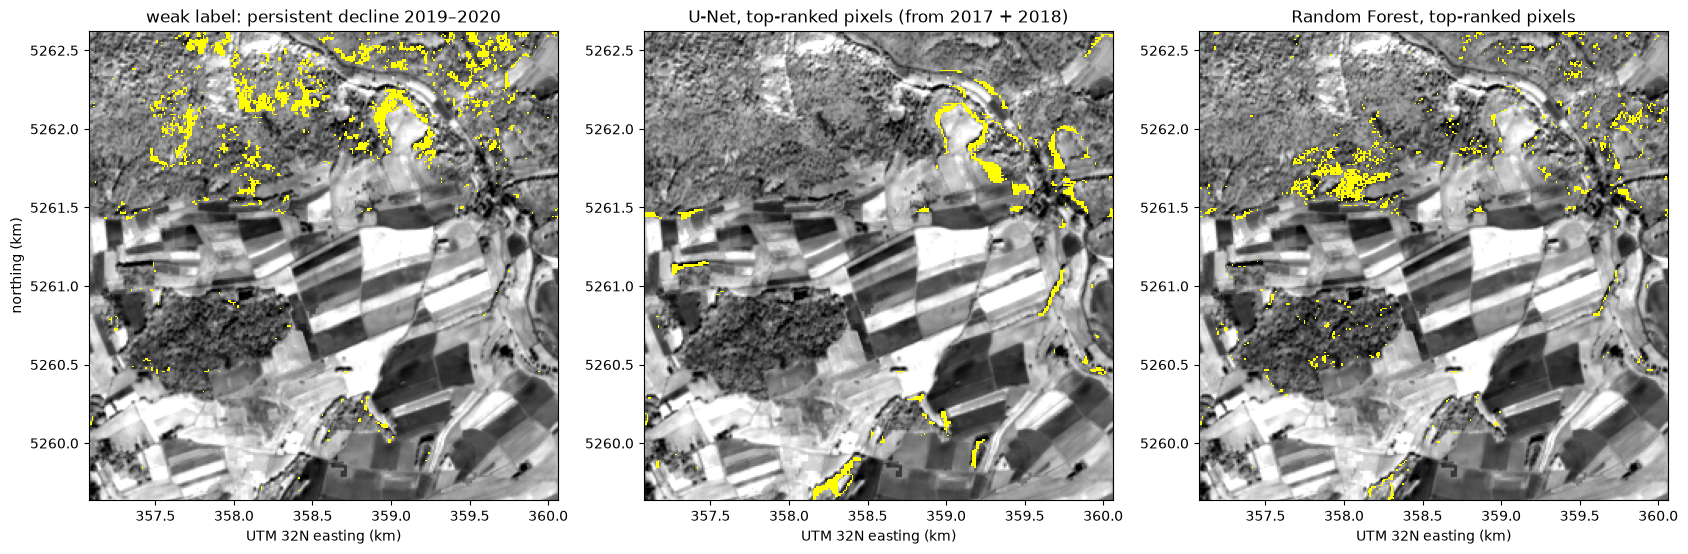

In [13]:
# zoom on the densest decline area for a readable comparison
S = 300; ref = to_img(yte_seg.astype("float32"))
best = max(((r, c) for r in range(0, Ht - S, 50) for c in range(0, Wt - S, 50)), key=lambda rc: np.nansum(ref[rc[0]:rc[0] + S, rc[1]:rc[1] + S]))
sl = (slice(best[0], best[0] + S), slice(best[1], best[1] + S)); ext_z = [xs[sl[1]][0] / 1e3, xs[sl[1]][-1] / 1e3, ys[sl[0]][-1] / 1e3, ys[sl[0]][0] / 1e3]
bg = su.stretch(L[TEST_AOI]["X"][5])   # NIR 2017
fig, ax = plt.subplots(1, 3, figsize=(17, 5.8))
for a, (img, t) in zip(ax, ((ref, "weak label: persistent decline 2019–2020"), (to_img(unet_cls.astype("float32")), "U-Net, top-ranked pixels (from 2017 + 2018)"),
                            (to_img(rf_cls.astype("float32")), "Random Forest, top-ranked pixels"))):
    a.imshow(bg[sl], cmap="gray", extent=ext_z)
    a.imshow(np.where(img[sl] == 1, 1.0, np.nan), cmap="autumn", vmin=0, vmax=1, extent=ext_z, interpolation="nearest")
    a.set_title(t); a.set_xlabel("UTM 32N easting (km)")
ax[0].set_ylabel("northing (km)")
plt.tight_layout(); plt.savefig(su.FIGS / "08_segmentation_example.png", dpi=150); plt.show()

## Save a summary of all three parts

In [14]:
summary = dict(regression_test_ajoie=reg_tbl.to_dict("records"), embedding_change=emb_change,
               embedding_vs_handmade=emb_tbl.to_dict("records"), segmentation_test_ajoie=seg_tbl.to_dict("records"),
               n_pixels=dict(train=len(Xtr_df), val=len(Xva_df), test=len(Xte_df)))
(su.TABLES / "08_summary.json").write_text(json.dumps(summary, indent=2, default=float))
print("saved", su.TABLES / "08_summary.json")

saved /Users/davidleu/Desktop/sds320-project/results/tables/08_summary.json


## Interpretation (run of 15 Nov 2026)

**A · Regression.** On the Ajoie, which no model saw during training:

| Model | R² | MAE (ΔNDVI) |
|---|---|---|
| Mean of the training target | −0.02 | 0.035 |
| Linear: ΔNDVI 2018 carried forward | 0.51 | 0.025 |
| Random Forest, pixel features | 0.61 | 0.022 |
| U-Net ResNet-34 | 0.38 | 0.026 |

- Half of the 2019 change is explained by the 2018 change alone. The Random Forest adds ten points of R² with the other bands.
- The U-Net is the weakest learned model. With 583 training tiles and a target that is noisy at pixel level, spatial context does not pay off, and the network also has to learn "zero change" for non-forest pixels because the loss cannot be masked.
- All models under-predict the strongest declines (Random Forest: +0.07 residual on the 5 % strongest declines), the usual regression to the mean. The pixels of most interest are the ones predicted worst.

**B · Embeddings.**
- Embedding change is only loosely related to ΔNDVI (Spearman 0.21). It still concentrates decline: 12.7 % of the 5 % least similar pixels are persistent-decline pixels, five times the average of 2.5 %. Embeddings react to any change in the yearly time series (harvest, regrowth, phenology), so they flag change in general.
- As features for the persistent-decline class (spatial block CV in the Ajoie tile, chance-level average precision 0.025): hand-made bands and indices 0.16, TESSERA 0.12, both together 0.17. The single value −ΔNDVI 2018 reaches 0.17 as well. The embeddings do not add information beyond the indices for this target.

**C · Segmentation.** Fricktal → Ajoie, chance-level average precision 0.027: U-Net 0.07, Random Forest 0.11, the ΔNDVI-2018 rule 0.15. The U-Net reaches a validation IoU of 0.53 on random tiles inside the Fricktal but transfers poorly, the same pattern as in notebook 06: random validation inside the training region overstates what the model does in a new region.

**Across all three parts** the simple, transparent baseline is as good as or better than the learned models, and persistent decline two years ahead is hard to predict from the drought-year image (best average precision 0.17). Two reasons: the weak labels are noisy and rare (2–3 %), and one region gives little training data. This does not show that deep learning is unsuited to the problem. It shows that at 10 m, without field labels, there is not enough signal for it to exploit.

**Limits of this notebook.** Targets are Sentinel-2 proxies. One training region, one test region. No tuning of architecture or augmentation. The embedding comparison covers one 0.1° tile.

## References
- geoai Python package (Q. Wu), documentation: https://opengeoai.org
- TESSERA pixel embeddings (University of Cambridge), accessed with the `geotessera` package: https://github.com/ucam-eo/geotessera
- Ronneberger, O., Fischer, P., Brox, T. (2015): U-Net: convolutional networks for biomedical image segmentation. MICCAI.
- Meyer, H., Pebesma, E. (2021): Predicting into unknown space? *Methods in Ecology and Evolution* 12, 1620–1633.